# 01 Recolección y calidad del dato

Austin Animal Center (Texas), ingresos y salidas de animales entre 2013 y 2018.

- Clasificación: resultado de salida (`outcome_type`).
- Regresión: días en el refugio (`time_in_shelter_days`).
- Entrada: `data/raw/aac_intakes_outcomes.csv`
- Salida: `data/interim/dev.csv` y `data/interim/test.csv`

## 1. Recolección de datos

Fuente: [Austin Animal Center Shelter Intakes and Outcomes (Kaggle)](https://www.kaggle.com/datasets/aaronschlegel/austin-animal-center-shelter-intakes-and-outcomes). Cada fila es un ingreso de un animal con su salida.

In [1]:
import hashlib
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit

from config import SEED

DATA = Path("..") / "data"
RAW_FILE = DATA / "raw" / "aac_intakes_outcomes.csv"

df = pd.read_csv(RAW_FILE)
# El SHA-256 identifica la copia exacta del archivo
print("SHA-256:", hashlib.sha256(RAW_FILE.read_bytes()).hexdigest())
df.head()

SHA-256: 1810fc9abbaf62cb706acab54dd2a1392fffc04951274358581a79bf6b2dcdab


,age_upon_outcome,animal_id_outcome,date_of_birth,outcome_subtype,outcome_type,sex_upon_outcome,age_upon_outcome_(days),age_upon_outcome_(years),age_upon_outcome_age_group,outcome_datetime,...,age_upon_intake_age_group,intake_datetime,intake_month,intake_year,intake_monthyear,intake_weekday,intake_hour,intake_number,time_in_shelter,time_in_shelter_days
0,10 years,A006100,2007-07-09 00:00:00,NaN,Return to Owner,Neutered Male,3650,10.0,"(7.5, 10.0]",2017-12-07 14:07:00,...,"(7.5, 10.0]",2017-12-07 00:00:00,12,2017,2017-12,Thursday,14,1.0,0 days 14:07:00.000000000,0.588194
1,7 years,A006100,2007-07-09 00:00:00,NaN,Return to Owner,Neutered Male,2555,7.0,"(5.0, 7.5]",2014-12-20 16:35:00,...,"(5.0, 7.5]",2014-12-19 10:21:00,12,2014,2014-12,Friday,10,2.0,1 days 06:14:00.000000000,1.259722
2,6 years,A006100,2007-07-09 00:00:00,NaN,Return to Owner,Neutered Male,2190,6.0,"(5.0, 7.5]",2014-03-08 17:10:00,...,"(5.0, 7.5]",2014-03-07 14:26:00,3,2014,2014-03,Friday,14,3.0,1 days 02:44:00.000000000,1.113889
3,10 years,A047759,2004-04-02 00:00:00,Partner,Transfer,Neutered Male,3650,10.0,"(7.5, 10.0]",2014-04-07 15:12:00,...,"(7.5, 10.0]",2014-04-02 15:55:00,4,2014,2014-04,Wednesday,15,1.0,4 days 23:17:00.000000000,4.970139
4,16 years,A134067,1997-10-16 00:00:00,NaN,Return to Owner,Neutered Male,5840,16.0,"(15.0, 17.5]",2013-11-16 11:54:00,...,"(15.0, 17.5]",2013-11-16 09:02:00,11,2013,2013-11,Saturday,9,1.0,0 days 02:52:00.000000000,0.119444


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 79672 entries, 0 to 79671
Data columns (total 41 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   age_upon_outcome            79672 non-null  str    
 1   animal_id_outcome           79672 non-null  str    
 2   date_of_birth               79672 non-null  str    
 3   outcome_subtype             36348 non-null  str    
 4   outcome_type                79662 non-null  str    
 5   sex_upon_outcome            79671 non-null  str    
 6   age_upon_outcome_(days)     79672 non-null  int64  
 7   age_upon_outcome_(years)    79672 non-null  float64
 8   age_upon_outcome_age_group  79672 non-null  str    
 9   outcome_datetime            79672 non-null  str    
 10  outcome_month               79672 non-null  int64  
 11  outcome_year                79672 non-null  int64  
 12  outcome_monthyear           79672 non-null  str    
 13  outcome_weekday             79672 non-null

| Grupo | Columnas | Uso |
|---|---|---|
| Objetivos | `outcome_type`, `time_in_shelter_days` | Lo que se predice |
| Conocidas al ingreso | `animal_type`, `breed`, `color`, `sex_upon_intake`, `age_upon_intake_(days)`, `intake_type`, `intake_condition`, `intake_datetime`, `intake_month`, `intake_hour`, `intake_number`, `found_location`, `date_of_birth` | Entradas candidatas |
| Identificador | `animal_id_intake` | Solo para agrupar en la partición |
| Conocidas al salir | `outcome_*`, `sex_upon_outcome`, `age_upon_outcome*`, `time_in_shelter` | Fuga, no se usan como entradas |
| Redundantes | `age_upon_intake`, `age_upon_intake_(years)`, `age_upon_intake_age_group`, `intake_monthyear`, `intake_weekday`, `intake_year`, `dob_*`, `count` | Derivadas de otras columnas |

## 2. Particionado

Un animal puede ingresar varias veces, así que se separa por `animal_id_intake`: 80 % desarrollo y 20 % test. Test no se mira hasta la evaluación final.

In [3]:
# Cada animal queda completo en desarrollo o en test
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
dev_idx, test_idx = next(splitter.split(df, groups=df["animal_id_intake"]))
dev = df.iloc[dev_idx].copy()
test = df.iloc[test_idx].copy()
del df

assert set(dev["animal_id_intake"]).isdisjoint(test["animal_id_intake"])
print("Desarrollo:", dev.shape, "Test:", test.shape)

Desarrollo: (63717, 41) Test: (15955, 41)


## 3. Calidad del dato

Solo sobre desarrollo.

In [4]:
missing = dev.isna().sum()
missing[missing > 0]

outcome_subtype     34627
outcome_type            8
sex_upon_outcome        1
sex_upon_intake         1
dtype: int64

In [5]:
intake_time = pd.to_datetime(dev["intake_datetime"])
outcome_time = pd.to_datetime(dev["outcome_datetime"])
birth_date = pd.to_datetime(dev["date_of_birth"])

rules = {
    "time_in_shelter_days >= 0": dev["time_in_shelter_days"] >= 0,
    "salida después del ingreso": outcome_time >= intake_time,
    "nacimiento antes del ingreso": birth_date <= intake_time,
    "intake_hour igual a la hora de intake_datetime": dev["intake_hour"] == intake_time.dt.hour,
    "intake_month igual al mes de intake_datetime": dev["intake_month"] == intake_time.dt.month,
}
violations = pd.Series({name: int((~passed).sum()) for name, passed in rules.items()}, name="violations")
violations

time_in_shelter_days >= 0                           0
salida después del ingreso                          0
nacimiento antes del ingreso                       68
intake_hour igual a la hora de intake_datetime    401
intake_month igual al mes de intake_datetime      114
Name: violations, dtype: int64

In [6]:
pd.Series({
    "filas repetidas": dev.duplicated().sum(),
    "sex_upon_intake Unknown": (dev["sex_upon_intake"] == "Unknown").sum(),
    "razas distintas": dev["breed"].nunique(),
    "colores distintos": dev["color"].nunique(),
})

filas repetidas              28
sex_upon_intake Unknown    5435
razas distintas            1946
colores distintos           488
dtype: int64

In [7]:
# Reglas críticas: si fallan, se detiene el notebook
assert violations["time_in_shelter_days >= 0"] == 0
assert violations["salida después del ingreso"] == 0

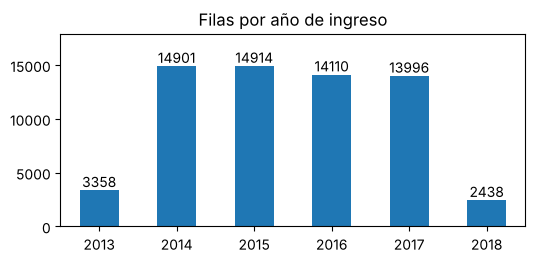

In [8]:
fig, ax = plt.subplots(figsize=(6, 2.5), dpi=100)
intake_time.dt.year.value_counts().sort_index().plot.bar(ax=ax, rot=0, xlabel="", title="Filas por año de ingreso")
ax.bar_label(ax.containers[0])
ax.margins(y=0.2)
plt.show()

## 4. Guardar particiones

In [9]:
dev.to_csv(DATA / "interim" / "dev.csv", index=False)
test.to_csv(DATA / "interim" / "test.csv", index=False)

## 5. Hallazgos para el notebook 02

| Hallazgo | Filas en desarrollo | Pendiente |
|---|---|---|
| Columnas conocidas al salir | 14 columnas | Excluir como entradas (fuga) |
| `outcome_type` ausente | 8 | Sin objetivo, fuera de la clasificación |
| Filas repetidas | 28 | Eliminar o justificar |
| Nacimiento posterior al ingreso | 68 | Edad dudosa |
| `intake_hour` y `intake_month` distintos de `intake_datetime` | 401 y 114 | Usar una sola fuente de fecha y hora |
| `sex_upon_intake` = Unknown | 5435 (8,53 %) | Categoría propia o ausente |
| Alta cardinalidad | 1946 razas, 488 colores | Agrupar |
| Años parciales | 2013 (desde octubre) y 2018 (hasta marzo) | Tenerlo en cuenta al comparar por año |